In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

file_path = "/home/richard/Netflix_Fresh/data/cleaned/netflix_cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nContent rating values:")
print(df["rating"].value_counts())

print("\nMissing rating values:", df["rating"].isna().sum())

Dataset loaded successfully!
Dataset shape: (8787, 10)

Content rating values:
rating
TV-MA       3205
TV-14       2155
TV-PG        861
R            798
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Missing rating values: 0


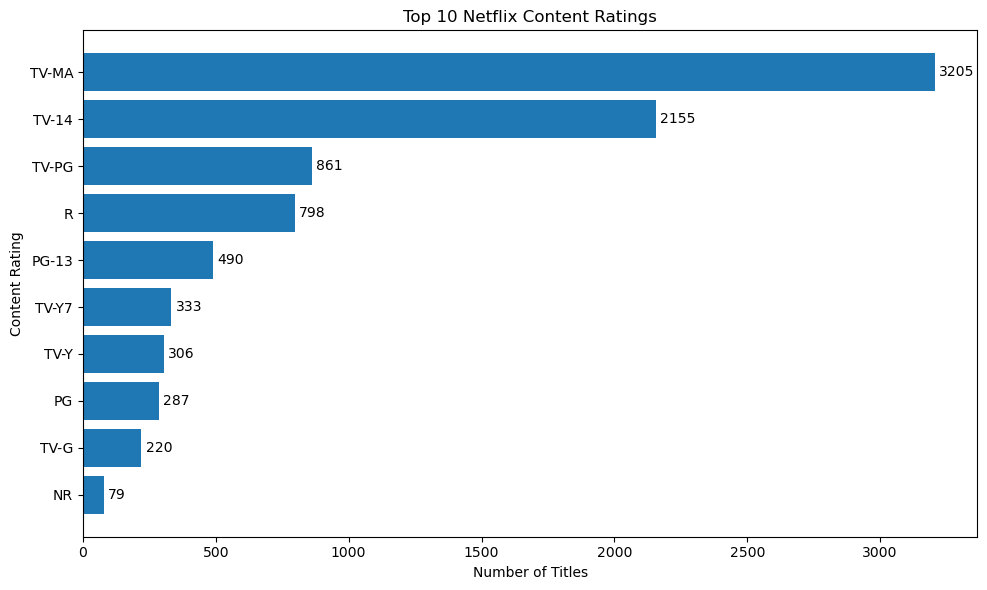

In [2]:
# Count titles by rating and select the top 10
rating_counts = df["rating"].value_counts()
top_10_ratings = rating_counts.head(10).sort_values()

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))
bars = plt.barh(top_10_ratings.index, top_10_ratings.values)

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")
plt.bar_label(bars, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

In [3]:
# Calculate the total number of titles with ratings
total_rated_titles = rating_counts.sum()

# Calculate percentages for the top 10 ratings
top_10_rating_percentages = (
    rating_counts.head(10) / total_rated_titles
) * 100

print("Top 10 Content Ratings by Percentage")
print(top_10_rating_percentages.round(2).astype(str) + "%")

print("\nTotal rated titles:", total_rated_titles)

Top 10 Content Ratings by Percentage
rating
TV-MA    36.47%
TV-14    24.52%
TV-PG      9.8%
R         9.08%
PG-13     5.58%
TV-Y7     3.79%
TV-Y      3.48%
PG        3.27%
TV-G       2.5%
NR         0.9%
Name: count, dtype: object

Total rated titles: 8787


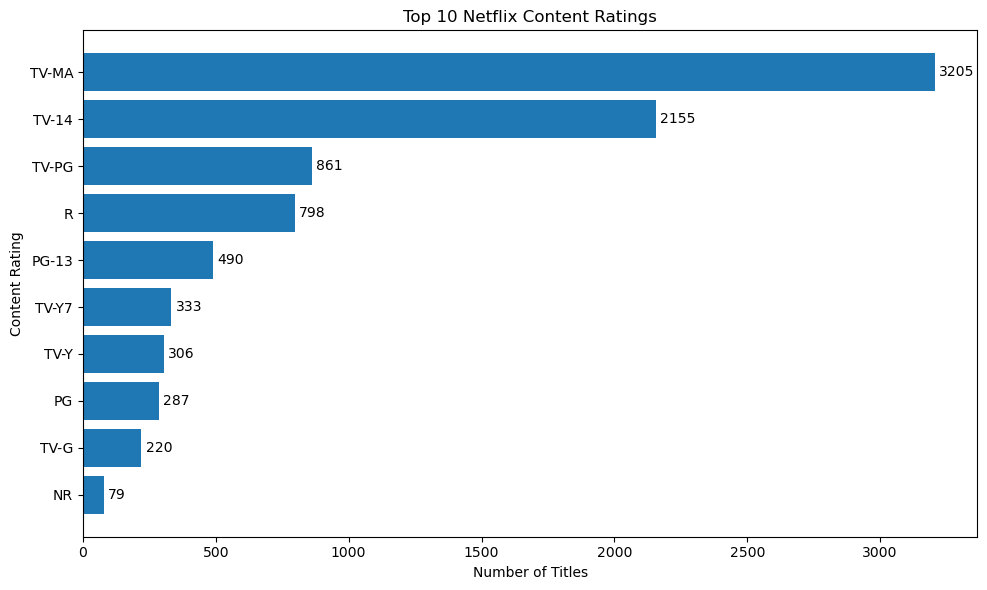

Rating chart saved successfully!
File location: /home/richard/Netflix_Fresh/outputs/figures/top_10_content_ratings.png


In [4]:
# Create the output directory
output_dir = "/home/richard/Netflix_Fresh/outputs/figures"
os.makedirs(output_dir, exist_ok=True)

# Create the chart
plt.figure(figsize=(10, 6))
bars = plt.barh(top_10_ratings.index, top_10_ratings.values)

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")
plt.bar_label(bars, fmt="%d", padding=3)

plt.tight_layout()

# Save the chart
chart_path = os.path.join(output_dir, "top_10_content_ratings.png")
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Rating chart saved successfully!")
print("File location:", chart_path)

In [5]:
# Remove records with missing genre information
genre_df = df.dropna(subset=["listed_in"]).copy()

# Split titles with multiple genres
genre_df["listed_in"] = genre_df["listed_in"].str.split(", ")

# Put each genre on its own row
genre_df = genre_df.explode("listed_in")

# Count titles associated with each genre
genre_counts = genre_df["listed_in"].value_counts()

print("Number of unique genres:", genre_counts.size)

print("\nTop 10 Netflix genres:")
print(genre_counts.head(10))

Number of unique genres: 42

Top 10 Netflix genres:
listed_in
International Movies        2752
Dramas                      2424
Comedies                    1673
International TV Shows      1348
Documentaries                869
Action & Adventure           859
TV Dramas                    761
Independent Movies           755
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


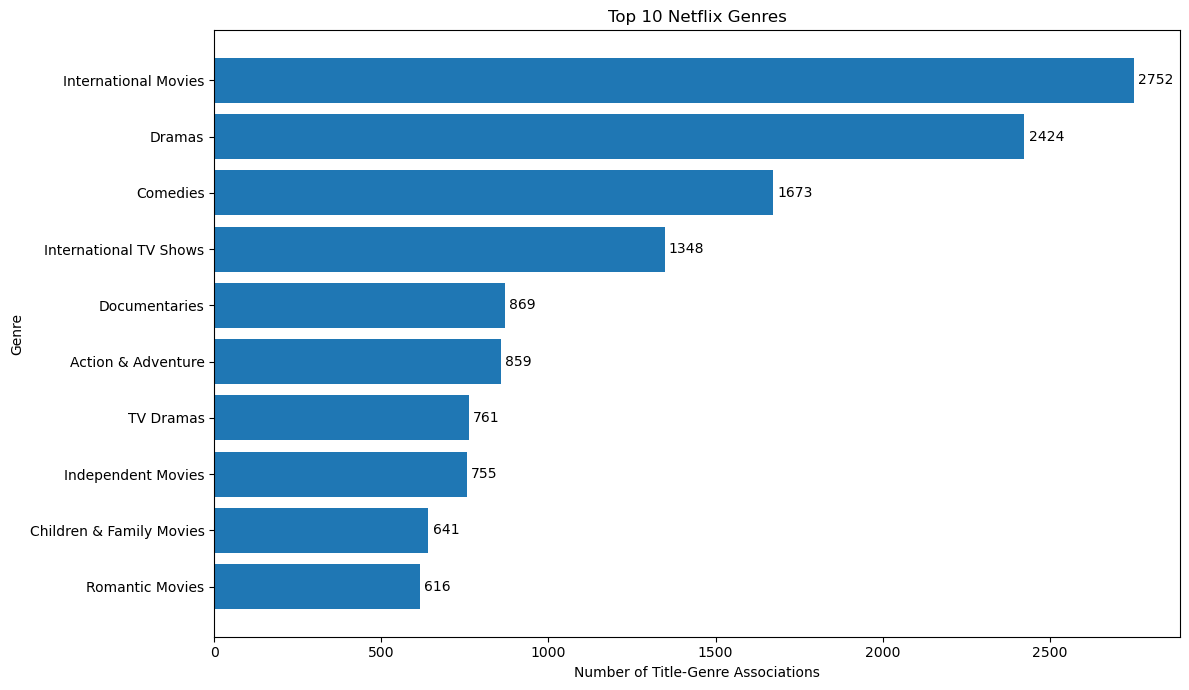

In [6]:
# Select the top 10 genres
top_10_genres = genre_counts.head(10).sort_values()

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))
bars = plt.barh(top_10_genres.index, top_10_genres.values)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Title-Genre Associations")
plt.ylabel("Genre")
plt.bar_label(bars, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

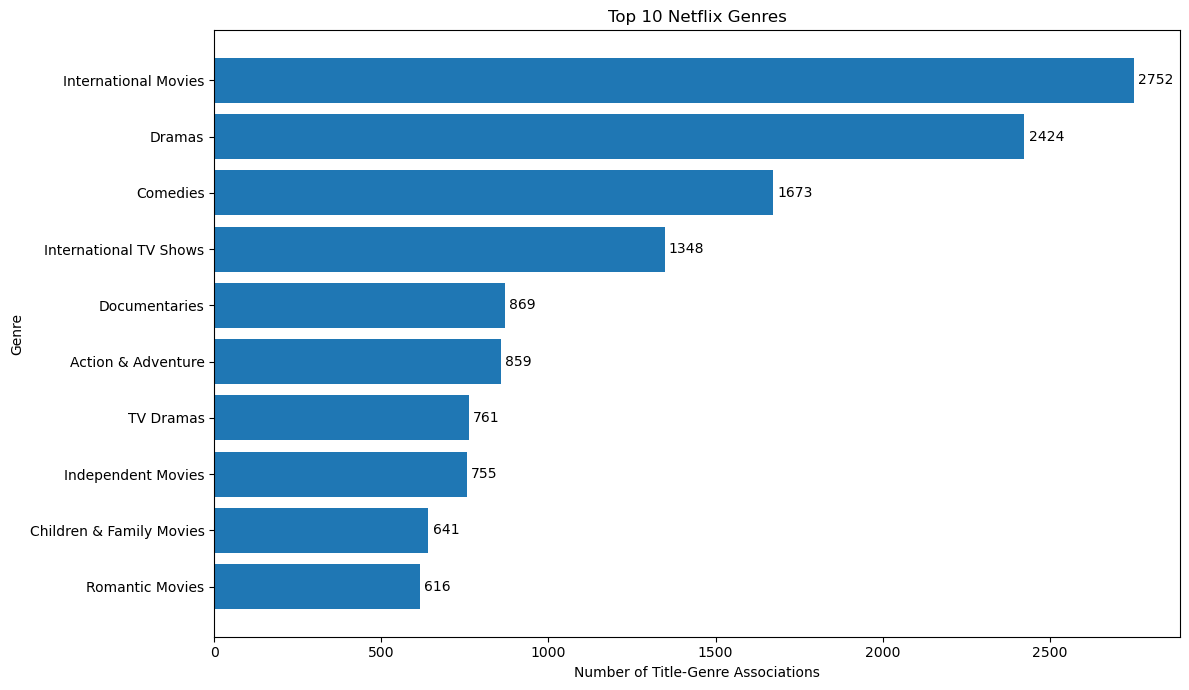

Genre chart saved successfully!
File location: /home/richard/Netflix_Fresh/outputs/figures/top_10_genres.png


In [7]:
# Define the output directory
output_dir = "/home/richard/Netflix_Fresh/outputs/figures"
os.makedirs(output_dir, exist_ok=True)

# Create the chart
plt.figure(figsize=(12, 7))
bars = plt.barh(top_10_genres.index, top_10_genres.values)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Title-Genre Associations")
plt.ylabel("Genre")
plt.bar_label(bars, fmt="%d", padding=3)

plt.tight_layout()

# Save the chart
chart_path = os.path.join(output_dir, "top_10_genres.png")
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Genre chart saved successfully!")
print("File location:", chart_path)

## Business Insights: Netflix Rating and Genre Analysis

### Key Findings

**Content Ratings**
- TV-MA was the most common rating, with 3,205 titles (36.47%).
- TV-14 ranked second, with 2,155 titles (24.52%).
- TV-PG ranked third, with 861 titles (9.80%).

**Genres**
- International Movies was the most frequently listed genre, with 2,752 title-genre associations.
- Dramas ranked second, with 2,424 associations.
- Comedies ranked third, with 1,673 associations.

### Business Recommendations

1. Analyze audience engagement by rating to understand which types of content attract viewers.
2. Evaluate opportunities to expand international content and drama offerings based on regional audience preferences.
3. Use viewing data and subscriber demographics alongside catalog counts before making content investment decisions.
4. Maintain a range of ratings and genres to serve different audience groups.

### Conclusion

The analysis shows that TV-MA and TV-14 are the most common content ratings, while International Movies, Dramas, and Comedies are the most frequently listed genres. These findings describe the composition of the Netflix catalog; they do not establish viewing popularity, audience preference, or profitability.

**Methodological Note:** Titles associated with multiple genres were counted once for each listed genre. Genre totals therefore represent title-genre associations rather than unique titles across all genres.

In [8]:
# Create the output directory
output_dir = "/home/richard/Netflix_Fresh/outputs"
os.makedirs(output_dir, exist_ok=True)

# Create a table of rating counts and percentages
rating_results = rating_counts.rename_axis(
    "rating"
).reset_index(name="title_count")

rating_results["percentage"] = (
    rating_results["title_count"] / total_rated_titles
) * 100

rating_results["percentage"] = rating_results["percentage"].round(2)

# Export to CSV
rating_csv_path = os.path.join(output_dir, "rating_analysis.csv")
rating_results.to_csv(rating_csv_path, index=False)

print("Rating analysis exported successfully!")
print("Total ratings:", len(rating_results))
print("Saved to:", rating_csv_path)

Rating analysis exported successfully!
Total ratings: 14
Saved to: /home/richard/Netflix_Fresh/outputs/rating_analysis.csv


In [9]:
# Create a table of genre counts
genre_results = genre_counts.rename_axis(
    "genre"
).reset_index(name="title_genre_associations")

# Export to CSV
genre_csv_path = os.path.join(output_dir, "genre_analysis.csv")
genre_results.to_csv(genre_csv_path, index=False)

print("Genre analysis exported successfully!")
print("Number of genres:", len(genre_results))
print("Saved to:", genre_csv_path)

Genre analysis exported successfully!
Number of genres: 42
Saved to: /home/richard/Netflix_Fresh/outputs/genre_analysis.csv


In [10]:
rating_check = pd.read_csv(
    "/home/richard/Netflix_Fresh/outputs/rating_analysis.csv"
)

genre_check = pd.read_csv(
    "/home/richard/Netflix_Fresh/outputs/genre_analysis.csv"
)

print("Rating analysis:", rating_check.shape)
print("Genre analysis:", genre_check.shape)

print("\nRating analysis preview:")
display(rating_check.head())

print("\nGenre analysis preview:")
display(genre_check.head())

Rating analysis: (14, 3)
Genre analysis: (42, 2)

Rating analysis preview:


,rating,title_count,percentage
0,TV-MA,3205,36.47
1,TV-14,2155,24.52
2,TV-PG,861,9.80
3,R,798,9.08
4,PG-13,490,5.58



Genre analysis preview:


,genre,title_genre_associations
0,International Movies,2752
1,Dramas,2424
2,Comedies,1673
3,International TV Shows,1348
4,Documentaries,869
